# Laboratorio 19. Agrupamiento de flores con k-means

**Asignatura:** Analítica de Datos  
**Docente:** Luis Miguel Gómez Meneses  
**Universidad Cooperativa de Colombia**  
**Duración máxima:** 20 minutos

## Objetivo

Aplicar k-means para agrupar flores según la similitud de sus
medidas e interpretar las características de los grupos encontrados.

## 1. Importación de librerías

Utilizaremos las siguientes herramientas:

- **matplotlib.pyplot:** para visualizar las flores y los grupos.
- **load_iris:** para cargar la base de datos Iris.
- **StandardScaler:** para estandarizar las variables.
- **KMeans:** para realizar el agrupamiento.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

## 2. Carga y reconocimiento de los datos

Utilizaremos la base de datos **Iris**, donde cada fila representa
una flor.

Seleccionaremos dos variables para poder representar las flores
en un gráfico de dispersión:

- **Longitud del pétalo**, en centímetros.
- **Ancho del pétalo**, en centímetros.

No incluiremos la especie entre las variables utilizadas para
formar los grupos.

In [2]:
iris = load_iris(as_frame=True)
X = iris.data[
    ["petal length (cm)", "petal width (cm)"]
].copy()
X.columns = ["longitud_petalo", "ancho_petalo"]
print("Número de flores:", X.shape[0])
print("Número de variables:", X.shape[1])
# Mostrar las primeras cinco filas.
display(X.head())

Número de flores: 150
Número de variables: 2


,longitud_petalo,ancho_petalo
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


### Preguntas de exploración

1. ¿Qué representa cada fila y en qué unidades están expresadas
   las variables?

2. Si dos flores tienen medidas de pétalo muy parecidas,
   ¿esperarías que quedaran en el mismo grupo? ¿Por qué?

**Respuestas:**

1.
2.

## 3. Visualización de las flores

Construiremos un gráfico de dispersión:

- El eje horizontal representa la **longitud del pétalo**.
- El eje vertical representa el **ancho del pétalo**.
- Cada punto representa una **flor**.

Todas las flores tendrán el mismo color porque todavía no hemos
aplicado k-means.

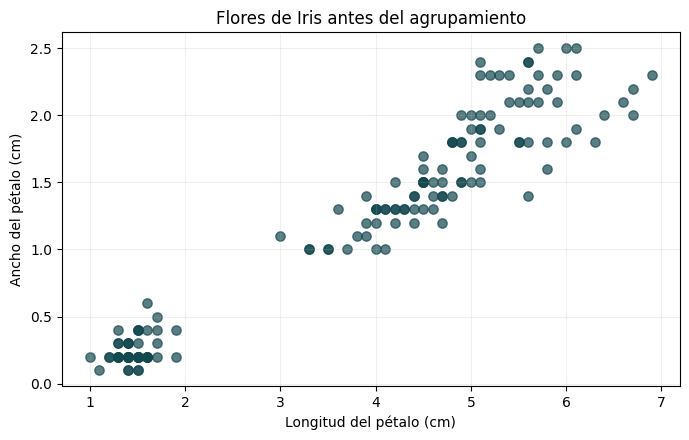

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(
    X["longitud_petalo"],
    X["ancho_petalo"],
    color="#14484F",
    alpha=0.7,
    s=45
)
ax.set_title("Flores de Iris antes del agrupamiento")
ax.set_xlabel("Longitud del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Preguntas de interpretación

1. ¿Observas algún conjunto de flores claramente separado de
   los demás? Describe sus medidas aproximadas.

2. ¿Se puede decidir con facilidad cuántos grupos formar,
   o hay regiones donde la separación es menos clara?

**Respuestas:**

1.
2.

## 4. Estandarización y aplicación de k-means

En este laboratorio estandarizaremos las variables para expresar
sus valores en unidades de desviación estándar.

Para cada variable, restamos su media y dividimos por su
desviación estándar. Este cálculo se realiza por columna.

Aunque ambas variables están en centímetros, pueden tener
dispersiones diferentes. Estandarizar es una decisión del análisis;
no es obligatorio en todos los problemas.

Después aplicaremos k-means con:

- **n_clusters=3:** solicitamos formar tres grupos.
- **n_init=10:** probamos diez inicializaciones y conservamos
  la solución con menor suma de distancias cuadradas a los centroides.
- **random_state=42:** fijamos la semilla para reproducir el resultado.

Elegimos tres grupos para practicar. Esto no demuestra que
tres sea el mejor número de grupos para estos datos.

In [4]:
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)
modelo = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)
grupos = modelo.fit_predict(X_escalado)
resultados = X.copy()
resultados["grupo"] = grupos
display(resultados.head())

,longitud_petalo,ancho_petalo,grupo
0,1.4,0.2,1
1,1.4,0.2,1
2,1.3,0.2,1
3,1.5,0.2,1
4,1.4,0.2,1


### Interpretación de la nueva columna

La columna **grupo** indica el agrupamiento asignado a cada flor.

Los números **0, 1 y 2** son identificadores: no representan
un orden ni corresponden automáticamente a las especies.

### Preguntas

1. ¿El algoritmo descubrió por sí solo cuántos grupos formar
   o nosotros le indicamos esa cantidad? ¿En qué instrucción?

2. ¿Se utilizó la especie de las flores para formar los grupos?
   ¿Qué información utilizó el algoritmo?

**Respuestas:**

1.
2.

## 5. ¿Cómo se forman los grupos?

Observaremos una ejecución de k-means paso a paso:

1. Seleccionamos tres centroides iniciales.
2. Asignamos cada flor al centroide más cercano.
3. Recalculamos cada centroide como el promedio de su grupo.
4. Repetimos hasta que los centroides se estabilicen.

### ¿Qué debemos observar?

- Los puntos representan flores y permanecen en su posición.
- El color indica el grupo asignado a cada flor.
- Las marcas **X** representan los centroides.
- Los centroides se desplazan cuando recalculamos los promedios.

Los ejes muestran las medidas estandarizadas: sus valores
representan desviaciones estándar respecto a la media.

Esta animación muestra una ejecución didáctica con una sola
inicialización. El modelo del bloque anterior probó diez.

**Ejecuta la siguiente celda y pulsa el botón de reproducción.
Puedes pausar o avanzar paso a paso.**

In [6]:
Z = X_escalado
colores = np.array(["#14484F", "#C2571A", "#6B7A7C"])
rng = np.random.default_rng(42)
indices = rng.choice(len(Z), size=3, replace=False)
centros = Z[indices].copy()
historial = [
    (None, centros.copy(), "Inicio: centroides seleccionados")
]
for paso in range(1, 31):
    distancias = (
        (Z[:, None, :] - centros[None, :, :]) ** 2
    ).sum(axis=2)
    etiquetas = distancias.argmin(axis=1)
    historial.append((
        etiquetas.copy(),
        centros.copy(),
        f"Iteración {paso}: asignar flores"
    ))
    nuevos = centros.copy()
    for j in range(3):
        if np.any(etiquetas == j):
            nuevos[j] = Z[etiquetas == j].mean(axis=0)
    historial.append((
        etiquetas.copy(),
        nuevos.copy(),
        f"Iteración {paso}: actualizar centroides"
    ))
    estable = np.allclose(
        centros, nuevos, rtol=0, atol=1e-8
    )
    centros = nuevos
    if estable:
        historial[-1] = (
            etiquetas.copy(),
            centros.copy(),
            "Resultado final: centroides estables"
        )
        break
fig, ax = plt.subplots(figsize=(7, 5))
puntos = ax.scatter(
    Z[:, 0], Z[:, 1],
    color="#B7BFC0",
    s=45,
    alpha=0.75
)
iniciales = historial[0][1]
marcas = ax.scatter(
    iniciales[:, 0], iniciales[:, 1],
    c=colores,
    marker="X",
    s=250,
    edgecolors="black",
    linewidths=1.2
)
ax.set_xlabel("Longitud del pétalo (z)")
ax.set_ylabel("Ancho del pétalo (z)")
ax.set_title("Inicio: centroides seleccionados\nX = centroides")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
fig.tight_layout()
def actualizar(i):
    etiquetas, centros, titulo = historial[i]

    puntos.set_color(
        "#B7BFC0" if etiquetas is None else colores[etiquetas]
    )

    marcas.set_offsets(centros)
    ax.set_title(titulo + "\nX = centroides")

    return puntos, marcas

animacion = FuncAnimation(
    fig,
    actualizar,
    frames=len(historial),
    interval=1300,
    repeat=False
)

plt.close(fig)
display(HTML(animacion.to_jshtml(default_mode="once")))

### Preguntas sobre la animación

1. Si una flor cambia de color, ¿qué cambió: sus medidas
   o el grupo al que pertenece?

2. ¿Qué ocurre con el movimiento de los centroides al llegar
   a las últimas iteraciones?

**Respuestas:**

1.
2.

## 6. ¿Cuántos grupos elegir? Método del codo

Hasta ahora elegimos tres grupos para practicar. Vamos a explorar
qué sucede al utilizar diferentes valores de k.

Ajustaremos modelos con **1 a 8 grupos** y calcularemos su
**inercia**: la suma de las distancias cuadradas de las flores
al centroide de su grupo.

Una inercia menor indica grupos más compactos según las
variables y la escala utilizadas.

### ¿Qué buscamos?

Buscamos una zona donde agregar más grupos produzca una reducción
mucho menor de la inercia. Ese cambio de pendiente se conoce
como **codo**.

Cada punto del gráfico corresponde a un modelo ajustado con
un valor distinto de k.

El codo es una orientación visual: puede ser ambiguo y no
garantiza un único número correcto de grupos.

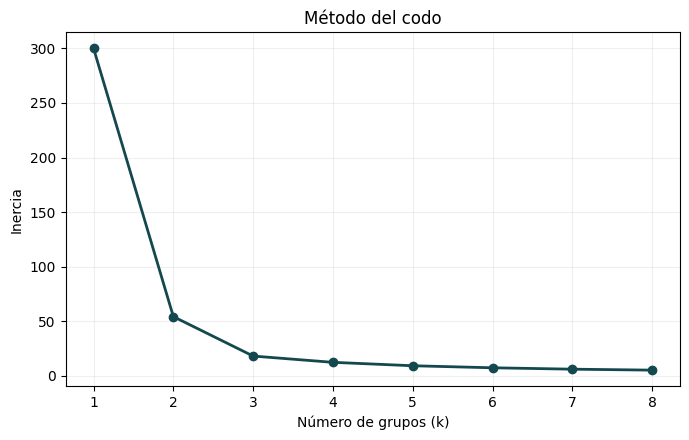

In [7]:
valores_k = range(1, 9)
inercias = []
for k in valores_k:
    modelo_k = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    modelo_k.fit(X_escalado)
    inercias.append(modelo_k.inertia_)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    list(valores_k),
    inercias,
    marker="o",
    color="#14484F",
    linewidth=2
)
ax.set_title("Método del codo")
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Inercia")
ax.set_xticks(list(valores_k))
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación del codo

1. ¿A partir de qué valor de k observas que la reducción de
   la inercia se vuelve mucho menor?

2. ¿Qué número de grupos elegirías a partir del gráfico?
   Justifica tu respuesta. Puedes mencionar si hay ambigüedad.

**Respuestas:**

1.
2.

## 7. Conclusión

Escribe una conclusión de tres líneas que explique:

- Cómo cambian los grupos y los centroides durante las iteraciones.
- Qué valor de k elegirías y por qué.
- Por qué los grupos encontrados no equivalen automáticamente
  a las especies de las flores.